In [2]:
## -- System dependencies --
import sys, os, gc
import torch

## -- Device-Agnostic (GPU/CPU) --
def get_system_info():
    if torch.cuda.is_available():
        return f"GPU: {torch.cuda.get_device_name(0)}"
    else:
        return f"CPU: {os.cpu_count()}"

get_system_info()

'CPU: 4'

In [3]:
try:
    from colorama import Fore, Style
except:
    !pip install -q colorama
    from colorama import Fore, Style

%matplotlib inline
%config InlineBackend.figure_format = 'svg'

In [4]:
## -- Data Manipulation --
import numpy as np, pandas as pd, random

## -- Visualization --
from IPython.display import display, Image
import matplotlib.pyplot as plt
import seaborn as sns

## -- Functional Tools --
import itertools
from tqdm.auto import tqdm
from time import time, sleep

## -- Machine Learning --
from sklearn.calibration import CalibrationDisplay
from sklearn.preprocessing import KBinsDiscretizer, TargetEncoder as skTE
from sklearn.metrics import roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay
from sklearn.model_selection import StratifiedKFold, train_test_split, cross_val_score

import warnings
warnings.simplefilter('ignore')
warnings.filterwarnings('ignore')

## -- Global Settings --
# sklearn.set_config(transform_output='pandas')
pd.set_option("display.max_columns", 100)
# sns.set_style("whitegrid")

In [ ]:
!uv pip install -U ydf

In [ ]:
import ydf

print(f"YDF version: {ydf.__version__}")

In [5]:
TEAL, GOLD, CORAL, BLUE, DARK, CRIM, MUTED, INK, PAPER = '#168c91','#e8b44f','#dc705a',\
                                                         'dodgerblue','#0B4F7A','crimson',\
                                                         '#627D98','#102A43','#faf9f5'
plt.rcParams.update({
    'figure.facecolor': PAPER,
    'axes.facecolor': PAPER,
    'savefig.facecolor': PAPER,
    'font.family': 'DejaVu Sans',
    'font.size': 8,
    'axes.titlesize': 11,
    'axes.titleweight': 'semibold',
    'axes.labelcolor': INK,
    'text.color': INK,
    'xtick.color': DARK,
    'ytick.color': DARK,
    'axes.edgecolor': MUTED,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'grid.color': MUTED,
    'patch.edgecolor': DARK,
    # 'patch.force_edgecolor': True,
    # 'patch.linewidth': 1.5,
    # 'figure.dpi':110,
    # 'savefig.dpi':160,
})
# CMAP = LinearSegmentedColormap.from_list('atlas', ['#f0f5ef','#a9d6ca',TEAL,INK])
# sns.set_palette([TEAL, GOLD, CORAL, BLUE, MUTED, CRIM, DARK, INK, PAPER])

## -- Set Global Seed --
CFG = {
    'FOLDS':  5,
    'SEED':   42,
    'GREEN':  '\033[32m',
    'YELLOW': '\033[33m',
    'RESET':  '\033[0m'
}

print(f"CLASSIC {CFG['GREEN']} GREEN {CFG['RESET']} {CFG['YELLOW']} YELLOW {CFG['RESET']}")

CLASSIC  GREEN   YELLOW 


In [6]:
## -- ⚠️ IMPORTANT: SELECT PLATFORM ⚠️ --
PLATFORM = "kaggle" # -> 'colab' 'kaggle'

if PLATFORM == "kaggle":
    PATH   = "/kaggle/input/competitions/playground-series-s6e11/"
    submit = pd.read_csv(PATH+"sample_submission.csv")
    train  = pd.read_csv(PATH+"train.csv")
    test   = pd.read_csv(PATH+"test.csv")
    ORIG_PATH = "/kaggle/input/datasets/uditjain13/credit-card-fraud-detection-2026/"
    orig = pd.read_csv(ORIG_PATH+"credit_card_fraud_2026.csv")
elif PLATFORM == "colab":
    from google.colab import drive
    drive.mount("/content/drive")
    PATH   = "/content/drive/MyDrive/-- shared_notebooks --/Ps6e11 | Credit Card Fraud/_fraud_data/"
    submit = pd.read_csv(PATH+"sample_submission.csv")
    train  = pd.read_csv(PATH+"train.csv")
    test   = pd.read_csv(PATH+"test.csv")
    orig   = pd.read_csv(PATH+"credit_card_fraud_2026.csv")
    
## =================================================================================

for (name, df) in {"Train": train, "Test": test, 'Orig': orig}.items(): #
    print(f"{name} shape: {df.shape}")

print(f"\nFrame type: {type(train)}")

float_cols = [
    'amount_usd', 'account_balance_usd',
    'hours_since_last_txn', 'distance_from_home_km',
    'velocity_score', 'merchant_risk_score',
]

int_cols = [
    'customer_age', 'card_age_months', 'time_of_day_hour', 'txn_count_last_24h',
    'cvv_retry_count', 'day_of_week', 'prior_disputes',
]

train.head()

Train shape: (699960, 26)
Test shape: (299984, 25)
Orig shape: (20000, 26)

Frame type: <class 'pandas.core.frame.DataFrame'>


,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud
0,0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,17,3,29.2,0,Groceries,Mastercard,OTP,POS,iPhone,False,False,False,False,False,False,0.0
1,1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,23,5,29.9,1,Online Retail,Visa,PIN,In-App,Android Phone,False,False,False,False,False,False,0.0
2,2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,15,0,24.1,0,Utilities,Visa,OTP,Online,Tablet,False,False,True,False,False,False,0.0
3,3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,7,3,41.9,0,Groceries,Mastercard,3D Secure,POS,Android Phone,False,False,False,False,False,False,0.0
4,4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,4,4,48.0,0,Electronics,Visa,3D Secure,Online,Windows PC,False,False,False,False,False,False,0.0


In [7]:
%%time

ID = 'id'
TARGET = 'is_fraud'

# X = train.drop([ID, TARGET], axis=1); train_id = train[ID]
# y = train[TARGET]
# X_test = test.drop([ID], axis=1); test_id = test[ID]

# print('-'*40)
# print("X      init shape:", X.shape)
# print("X_test init shape:", X_test.shape, "\n")

cat_cols = train.drop([ID, TARGET], axis=1).select_dtypes(include=['object', 'bool']).columns.tolist()
num_cols = train.drop([ID, TARGET], axis=1).select_dtypes(exclude=['object', 'bool']).columns.tolist()
base_cols = cat_cols + num_cols

float_cols = train.drop([ID, TARGET], axis=1).select_dtypes(include=['float']).columns.tolist()
int_cols = train.drop([ID, TARGET], axis=1).select_dtypes(include=['int']).columns.tolist()
obj_cols = train.drop([ID, TARGET], axis=1).select_dtypes(include=['object', 'bool']).columns.tolist()

print("init len(cat_cols):", len(cat_cols))
print("init len(num_cols):", len(num_cols))
print("init len(float_cols):", len(float_cols))
print("init len(int_cols):", len(int_cols))
print("init len(object_cols):", len(obj_cols))
print("init len(total cols):", len(base_cols))

init len(cat_cols): 11
init len(num_cols): 13
init len(float_cols): 6
init len(int_cols): 7
init len(object_cols): 11
init len(total cols): 24
CPU times: user 396 ms, sys: 149 ms, total: 545 ms
Wall time: 544 ms


In [8]:
train_len = len(train)
test_len  = len(test)

n_unique = train.nunique().sort_values()
n_unique

is_new_merchant                      2
is_fraud                             2
is_ai_generated_scam_attempt         2
billing_shipping_mismatch            2
ip_country_mismatch                  2
used_vpn                             2
is_foreign_transaction               2
cvv_retry_count                      4
auth_method                          5
prior_disputes                       5
card_type                            5
channel                              5
day_of_week                          7
device_type                          8
txn_count_last_24h                  12
merchant_category                   12
time_of_day_hour                    24
card_age_months                     49
customer_age                        64
velocity_score                     666
merchant_risk_score                950
hours_since_last_txn              3633
distance_from_home_km             4365
amount_usd                       13387
account_balance_usd              43317
id                       

In [9]:
def get_weights(y, y_true, opt='auto'):
    """
    y: Current y labels -> numpy array or series
    y_true: True labels -> numpy array or series
    opt: 'auto' generate weight or pass a custom dict -> label: weight
    """
    if opt != 'auto':
        class_weights = opt
        sample_weights = np.array([class_weights[label] for label in y])
        return class_weights
    else:
        classes_ = np.unique(y_true)
        weights_ = compute_class_weight('balanced', classes=classes_, y=y_true)
        class_weights = dict(zip(classes_, weights_))
        sample_weights = np.array([class_weights[label] for label in y])
        return class_weights

# ## -- Reduce data memory --
# def reduce_memory(df):
#     old_size = sys.getsizeof(df) / (1024*1024)
#     for c in tqdm(df.columns, desc='Reducing memory...'):
#         if df[c].dtype == np.int64:
#             ## -- Downcast Integer type ---
#             if df[c].min() > np.iinfo(np.int32).min and df[c].max() < np.iinfo(np.int32).max:
#                 df[c] = df[c].astype(np.int32)
#                 # if df[c].min() > np.iinfo(np.int16).min and df[c].max() < np.iinfo(np.int16).max:
#                 #     df[c] = df[c].astype(np.int16)
#                 #     if df[c].min() > np.iinfo(np.int8).min and df[c].max() < np.iinfo(np.int8).max:
#                 #         df[c] = df[c].astype(np.int8)
#         elif df[c].dtype == np.float64:
#             ## -- Downcast Float type -----
#             if df[c].min() > np.finfo(np.float32).min and df[c].max() < np.finfo(np.float32).max:
#                 df[c] = df[c].astype(np.float32)
#                 # if df[c].min() > np.finfo(np.float16).min and df[c].max() < np.finfo(np.float16).max:
#                 #     df[c] = df[c].astype(np.float16)

#     new_size = sys.getsizeof(df) / (1024**2)
#     print(f"Size before process: {old_size:.1f}MB\nSize after process : {new_size:.1f}MB\n")

#     return df

print('- Helper Functions Ready -')

- Helper Functions Ready -


In [10]:
# import pandas as pd
# from pandas.util import hash_pandas_object

# # Generate hashes
# hash1 = hash_pandas_object(train[base_cols], index=False)
# hash2 = hash_pandas_object(orig[base_cols], index=False)

# # Find rows in orig that are NOT present in train
# new_or_changed_rows = hash2.isin(hash1)

# # Get the actual data for those mismatched rows
# mismatched_orig_data = orig[new_or_changed_rows]
# display(mismatched_orig_data)

In [11]:
from sklearn.base import BaseEstimator, TransformerMixin ## ===== Target/Category Mean ENCODERS =====

class customTE(BaseEstimator, TransformerMixin):
    """
    Target Encoder that supports multiple aggregation functions,
    internal cross-validation for leakage prevention, and smoothing.

    Parameters
    ----------
    cols_to_encode : list of str
        List of column names to be target encoded.

    aggs : list of str, default=['mean']
        List of aggregation functions to apply. Any function accepted by
        pandas' `.agg()` method is supported, such as:
        'mean', 'std', 'var', 'min', 'max', 'skew', 'nunique',
        'count', 'sum', 'median'.
        Smoothing is applied only to the 'mean' aggregation.

    cv : int, default=5
        Number of folds for cross-validation in fit_transform.

    smooth : float or 'auto', default='auto'
        The smoothing parameter `m`. A larger value puts more weight on the
        global mean. If 'auto', an empirical Bayes estimate is used.

    drop_original : bool, default=False
        If True, the original columns to be encoded are dropped.
    """
    def __init__(self, cols_to_encode, aggs=['mean'], cv=5, smooth='auto', drop_original=False):
        self.cols_to_encode = cols_to_encode
        self.aggs = aggs
        self.cv = cv
        self.smooth = smooth
        self.drop_original = drop_original
        self.mappings_ = {}
        self.global_stats_ = {}

    def fit(self, X, y):
        """
        Learn mappings from the entire dataset.
        These mappings are used for the transform method on validation/test data.
        """
        temp_df = X.copy()
        temp_df['target'] = y

        # Learn global statistics for each aggregation
        for agg_func in self.aggs:
            self.global_stats_[agg_func] = y.agg(agg_func)

        # Learn category-specific mappings
        for col in self.cols_to_encode:
            self.mappings_[col] = {}
            for agg_func in self.aggs:
                mapping = temp_df.groupby(col)['target'].agg(agg_func)
                self.mappings_[col][agg_func] = mapping

        return self

    def transform(self, X):
        """
        Apply learned mappings to the data.
        Unseen categories are filled with global statistics.
        """
        X_transformed = X.copy()
        for col in self.cols_to_encode:
            for agg_func in self.aggs:
                new_col_name = f'TE_{col}_{agg_func}'
                map_series = self.mappings_[col][agg_func]
                X_transformed[new_col_name] = X[col].map(map_series)
                X_transformed[new_col_name].fillna(self.global_stats_[agg_func], inplace=True)

        if self.drop_original:
            X_transformed.drop(columns=self.cols_to_encode, inplace=True)

        return X_transformed

    def fit_transform(self, X, y):
        """
        Fit and transform the data using internal cross-validation to prevent leakage.
        """
        # First, fit on the entire dataset to get global mappings for transform method
        self.fit(X, y)

        # Initialize an empty DataFrame to store encoded features
        encoded_features = pd.DataFrame(index=X.index)

        kf = KFold(n_splits=self.cv, shuffle=True, random_state=42)

        for train_idx, val_idx in kf.split(X, y):
            X_trn, y_trn = X.iloc[train_idx], y.iloc[train_idx]
            X_val = X.iloc[val_idx]

            temp_df_train = X_trn.copy()
            temp_df_train['target'] = y_trn

            for col in self.cols_to_encode:
                # --- Calculate mappings only on the training part of the fold ---
                for agg_func in self.aggs:
                    new_col_name = f'TE_{col}_{agg_func}'

                    # Calculate global stat for this fold
                    fold_global_stat = y_trn.agg(agg_func)

                    # Calculate category stats for this fold
                    mapping = temp_df_train.groupby(col)['target'].agg(agg_func)

                    # --- Apply smoothing only for 'mean' aggregation ---
                    if agg_func == 'mean':
                        counts = temp_df_train.groupby(col)['target'].count()

                        m = self.smooth
                        if self.smooth == 'auto':
                            # Empirical Bayes smoothing
                            variance_between = mapping.var()
                            avg_variance_within = temp_df_train.groupby(col)['target'].var().mean()
                            if variance_between > 0:
                                m = avg_variance_within / variance_between
                            else:
                                m = 0  # No smoothing if no variance between groups

                        # Apply smoothing formula
                        smoothed_mapping = (counts * mapping + m * fold_global_stat) / (counts + m)
                        encoded_values = X_val[col].map(smoothed_mapping)
                    else:
                        encoded_values = X_val[col].map(mapping)

                    # Store encoded values for the validation fold
                    encoded_features.loc[X_val.index, new_col_name] = encoded_values.fillna(fold_global_stat)

        # Merge with original DataFrame
        X_transformed = X.copy()
        for col in encoded_features.columns:
            X_transformed[col] = encoded_features[col]

        if self.drop_original:
            X_transformed.drop(columns=self.cols_to_encode, inplace=True)

        return X_transformed


class CategoryMeanTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, cat_cols=None):
        self.cat_cols = cat_cols
        self.mappings_ = {}
    def fit(self, X, y):
        X = X.copy()
        if self.cat_cols is None:
            self.cat_cols = X.select_dtypes(include=['category']).columns.tolist()
        self.mappings_ = {}
        for col in self.cat_cols:
            df_temp = pd.DataFrame({col: X[col], 'y': y})
            group_means = df_temp.groupby(col, dropna=False)['y'].mean()
            sorted_categories = group_means.sort_values().index
            self.mappings_[col] = {cat: i for i, cat in enumerate(sorted_categories)}

        return self

    def transform(self, X, y=None):
        X = X.copy()
        for col, mapping in self.mappings_.items():
            if col in X.columns:
                X[col] = X[col].map(mapping)

        return X

In [12]:
## -- original_TE with factorization --
from typing import List, Optional, Tuple

def original_fcTE(
    orig: pd.DataFrame,
    df: pd.DataFrame,
    features: Optional[List[str]] = None,
    target: Optional[str] = None,
    aggs: Optional[List[str]] = None,
    fill_nan: bool = False,
) -> Tuple[pd.DataFrame, List[str]]:
    """
    Applies out-of-fold / external dataset target encoding (TE) from `orig` onto `df`.
    """
    X_df = df.copy()
    orig_df = orig.copy()  # Prevent mutating the caller's original DataFrame

    # 1. Early exit with consistent return signature (DataFrame, list)
    if not features or not aggs or target is None:
        return X_df, []

    if target not in orig_df.columns:
        raise ValueError(f"Target column '{target}' not found in `orig`.")

    # 2. Validate features exist in BOTH DataFrames
    valid_features = [
        col for col in features 
        if col in orig_df.columns and col in X_df.columns
    ]
    
    # Separate 'count' from target-dependent aggregations
    supported_target_aggs = {'mean', 'median', 'nunique', 'std', 'skew', 'max', 'min'}
    clean_aggs = [a.lower() for a in aggs]

    orig_cols = []
    new_features_dict = {}

    for col in tqdm(valid_features, desc="original_augmenting"):
        # Align categorical/object/bool dtypes safely only for needed columns
        if pd.api.types.is_object_dtype(X_df[col]) or \
           isinstance(X_df[col].dtype, pd.CategoricalDtype) or \
           pd.api.types.is_bool_dtype(X_df[col]):
            combined = pd.concat([X_df[col], orig_df[col]], ignore_index=True)
            codes, _ = pd.factorize(combined, sort=True)
            X_df[col] = codes[:len(X_df)]
            orig_df[col] = codes[len(X_df):]

        # Group once per feature instead of once per (feature, agg)
        grouped = orig_df.groupby(col, dropna=False)
        
        # Compute target aggregations in one vectorized pass
        target_aggs_to_run = [a for a in clean_aggs if a in supported_target_aggs]
        if target_aggs_to_run:
            try:
                agg_stats = grouped[target].agg(target_aggs_to_run)
                for agg_key in target_aggs_to_run:
                    new_col = f"oTE_{col}_{agg_key}"
                    # .map() preserves X_df's exact index and row order
                    new_features_dict[new_col] = X_df[col].map(agg_stats[agg_key])
                    orig_cols.append(new_col)
            except Exception as e:
                print(f"Warning: failed target aggs for col={col}: {e}")

        # Handle 'count' separately since it doesn't depend on `target`
        if 'count' in clean_aggs:
            new_col = f"oTE_{col}_count"
            counts = grouped.size()
            new_features_dict[new_col] = X_df[col].map(counts)
            orig_cols.append(new_col)

    # Concatenate all new columns at once to avoid DataFrame fragmentation
    if new_features_dict:
        new_cols_df = pd.DataFrame(new_features_dict, index=X_df.index)
        X_df = pd.concat([X_df, new_cols_df], axis=1)

    # 3. Fill missing values cleanly
    if fill_nan and orig_cols:
        global_mean = orig_df[target].mean()
        global_median = orig_df[target].median()

        fill_values = {}
        for c in orig_cols:
            if c.endswith(('_mean', '_max', '_min')):
                fill_values[c] = global_mean
            elif c.endswith('_median'):
                fill_values[c] = global_median
            else:
                fill_values[c] = 0

        X_df = X_df.fillna(value=fill_values)

    return X_df, orig_cols

print('-- Factorized augment function ready! --')

-- Factorized augment function ready! --


In [13]:
## -- original_TE with objects --
from typing import List, Optional, Tuple

def original_obTE(
    orig: pd.DataFrame,
    df: pd.DataFrame,
    features: Optional[List[str]] = None,
    target: Optional[str] = None,
    aggs: Optional[List[str]] = None,
    fill_nan: bool = False,
) -> Tuple[pd.DataFrame, List[str]]:
    """
    Applies external dataset target encoding (TE) from `orig` onto `df`
    while preserving original categorical/string dtypes.
    """
    X_df = df.copy()

    if not features or not aggs or target is None:
        return X_df, []

    if target not in orig.columns:
        raise ValueError(f"Target column '{target}' not found in `orig`.")

    valid_features = [
        col for col in features 
        if col in orig.columns and col in X_df.columns
    ]
    
    supported_target_aggs = {'mean', 'median', 'nunique', 'std', 'skew', 'max', 'min'}
    clean_aggs = [a.lower() for a in aggs]

    orig_cols = []
    new_features_dict = {}

    for col in tqdm(valid_features, desc="original_augmenting"):
        # Group directly on raw strings, objects, or categories (observed=True prevents cartesian blowups)
        grouped = orig.groupby(col, dropna=False, observed=True)
        
        target_aggs_to_run = [a for a in clean_aggs if a in supported_target_aggs]
        if target_aggs_to_run:
            try:
                agg_stats = grouped[target].agg(target_aggs_to_run)
                for agg_key in target_aggs_to_run:
                    new_col = f"oTE_{col}_{agg_key}"
                    # Convert Series to plain dict so CategoricalIndex mismatches don't cause issues
                    mapping_dict = agg_stats[agg_key].to_dict()
                    new_features_dict[new_col] = X_df[col].map(mapping_dict).astype('float32')
                    orig_cols.append(new_col)
            except Exception as e:
                print(f"Warning: failed target aggs for col={col}: {e}")

        if 'count' in clean_aggs:
            new_col = f"oTE_{col}_count"
            counts_dict = grouped.size().to_dict()
            new_features_dict[new_col] = X_df[col].map(counts_dict).astype('float32')
            orig_cols.append(new_col)

    if new_features_dict:
        new_cols_df = pd.DataFrame(new_features_dict, index=X_df.index)
        X_df = pd.concat([X_df, new_cols_df], axis=1)

    if fill_nan and orig_cols:
        global_mean = orig[target].mean()
        global_median = orig[target].median()

        fill_values = {}
        for c in orig_cols:
            if c.endswith(('_mean', '_max', '_min')):
                fill_values[c] = global_mean
            elif c.endswith('_median'):
                fill_values[c] = global_median
            else:
                fill_values[c] = 0

        X_df = X_df.fillna(value=fill_values)

    return X_df, orig_cols

print('-- Object augment function ready! --')

-- Object augment function ready! --


## FEATURE ENGINEERING

In [14]:
# ## -- Cyclic encoding --

# for df in [train, test]:
#     for p in [8, 12, 24]:
#         df[f"sleep_hours_sin_{p}"] = np.sin(2 * np.pi * df["sleep_hours"] / p).astype("float32")
#         df[f"sleep_hours_cos_{p}"] = np.cos(2 * np.pi * df["sleep_hours"] / p).astype("float32")

In [15]:
## -- NUMERIC TO CATEGORY for TargetEncoding -- ⚠️

FEATURES = [c for c in train.columns if c not in [ID, TARGET]]
print("Features before operation:", len(FEATURES))

combined = pd.concat([train, test], ignore_index=True)
## ------------------------------------------------------------
# -- Duplicate Nums as Cats --
nums_to_cats = []
select_nc = num_cols

for c in tqdm(select_nc, desc="nums_to_cats"):
    new_cat = f"{c}_CAT_"
    combined[new_cat], unique = pd.factorize(combined[c], sort=True)
    combined[new_cat] = combined[new_cat].astype('int32') #.astype('category')
    nums_to_cats.append(new_cat)
## ------------------------------------------------------------
train = combined.iloc[:train_len]
test  = combined.iloc[train_len:train_len+test_len].drop(columns=[TARGET])
# orig  = combined.iloc[train_len+test_len:]

del combined
print("Features after operation:", train.shape[1])

Features before operation: 24


nums_to_cats:   0%|          | 0/13 [00:00<?, ?it/s]

Features after operation: 39


In [16]:
# ## -- Frequency encoding -- ⚠️
# freq_cols = []

# combined = pd.concat([train, test], ignore_index=True)

# select_freq = cat_cols
# #, "Age", "Arrival Delay in Minutes", "Departure Delay in Minutes"]

# print("\nCreating frequencies (Safe Global Mapping)...")
# for col in select_freq:
#     n = f"{col}_FREQ_"
#     print(f"⧗ {n}", end="")

#     # Calculate frequencies using ONLY train
#     freq_map = train[col].value_counts(dropna=False, normalize=False).to_dict()

#     # Map the training-derived frequencies across all datasets safely
#     train[n] = train[col].map(freq_map).fillna(0).astype("float32")
#     test[n] = test[col].map(freq_map).fillna(0).astype("float32")
#     orig[n] = orig[col].map(freq_map).fillna(0).astype("float32")

#     freq_cols.append(n)
#     print()

# print(f"\n *** Total frequency features: {len(freq_cols)}")

In [17]:
# ## -- Factorize cat_cols -- ⚠️

# FEATURES = [c for c in train.columns if c not in [ID, TARGET]]
# print("Total features before operation:", len(FEATURES))

# combined = pd.concat([train, test, orig])
# ## ------------------------------------------------------------------------
# for c in tqdm(cat_cols, desc="factorize_cats"):
#     combined[c] = (pd.factorize(combined[c])[0]).astype('int32')

# ## ------------------------------------------------------------------------
# GROUP_COLS = []
# grouper  = 'Flight Distance'
# agg_cols = ['Class', 'Type of Travel'] + service_cols

# for col in agg_cols:
#     g_col = f"{col}_{grouper.split(' ')[0]}_GROUPBY".replace(" ", "")
#     combined[f"{g_col}_mean"] = combined.groupby([grouper])[col].transform('mean')
#     # combined[f"{g_col}_std"] = combined.groupby([grouper])[col].transform('std')
#     # combined[f"{g_col}_skew"] = combined.groupby(['Flight Distance'])[col].transform('skew')
#     GROUP_COLS.append(g_col)

# # for col in service_cols + ['Class', 'Type of Travel']:
# #     g_col = f"{col}_AGE_GROUPBY".replace(" ", "")
# #     combined[f"{g_col}_mean"] = combined.groupby(['Age'])[col].transform('mean')
#     # combined[f"{g_col}_std"] = combined.groupby(['Age'])[col].transform('std')
#     # combined[f"{g_col}_skew"] = combined.groupby(['Flight Distance'])[col].transform('skew')
#     # groupers.append(g_col)

# # FEATURES = list(set(FEATURES + GROUP_COLS))
# ## ------------------------------------------------------------------------

# for c in tqdm(cat_cols, desc="categorize_cats"):
#     combined[c] = combined[c].astype("category")

# train = combined.iloc[:train_len]
# test  = combined.iloc[train_len:train_len+test_len].drop(columns=[TARGET])
# orig  = combined.iloc[train_len+test_len:]

# del combined
# print("Total features after operation:", len(FEATURES))

In [18]:
# FEATURES = [c for c in train.columns if c not in [ID, TARGET]]

# combined = pd.concat([train, test, orig], ignore_index=True)
# digit_cols = []

# for col in num_cols:
#     scaled = np.rint(combined[col].fillna(0) * 10**4).astype("int64")
#     for k in range(-2, 3):
#         dig_col = f"{col}_DIGIT_{k}"
#         combined[dig_col] = (scaled // 10**(k+4) % 10).astype('int8') #.astype('category')
#         digit_cols.append(dig_col)

# train = combined.iloc[:train_len]
# test = combined.iloc[train_len:train_len+test_len].drop(columns=[TARGET])
# orig = combined.iloc[-len(orig):]

# # Check nunique, and find which ones are < 2
# unique_counts = train[digit_cols].nunique()
# drop_cols = unique_counts[unique_counts < 2].index.tolist()

# # update digit cols for keep
# digit_cols = [i for i in set(digit_cols) if i not in set(drop_cols)]

# # drop constant features
# train = train.drop(columns=drop_cols)
# test  = test.drop(columns=drop_cols)
# orig  = orig.drop(columns=drop_cols)

# del combined
# print(f"Total digit features: {len(digit_cols)}\n")

# train[digit_cols].nunique()

In [19]:
def digit_keys(df1, cols=float_cols):
    df = df1.copy()
    """How each number is written: six label-free keys per float column."""
    keys = {}
    for c in cols:
        units = np.rint(df[c].to_numpy() * 100).astype(np.int64)        # 1371.37 -> 137137
        integer = units // 100
        s = pd.Series(integer).astype(str)
        keys[f"{c}__int"] = integer                                      # 1371
        keys[f"{c}__int10"] = units // 1000                              # 137
        keys[f"{c}__tenths"] = units // 10                               # 13713
        keys[f"{c}__cents"] = units % 100                                # 37
        keys[f"{c}__lead1"] = (s.str.len() * 10 + s.str[0].astype(int)).to_numpy()     # 4|1
        keys[f"{c}__lead2"] = (s.str.len() * 100 + s.str[:2].astype(int)).to_numpy()   # 4|13

    new_df = pd.DataFrame(keys, index=df.index)
    full_df = pd.concat([df, new_df], axis=1)
    return full_df, [*keys.keys()]

train, digit_cols2 = digit_keys(train)
test, _ = digit_keys(test)

print(train.shape, test.shape)
train[digit_cols2].nunique()

(699960, 75) (299984, 74)


amount_usd__int                   1144
amount_usd__int10                  235
amount_usd__tenths                4599
amount_usd__cents                  100
amount_usd__lead1                   33
amount_usd__lead2                  217
hours_since_last_txn__int           51
hours_since_last_txn__int10          6
hours_since_last_txn__tenths       502
hours_since_last_txn__cents        100
hours_since_last_txn__lead1         15
hours_since_last_txn__lead2         51
distance_from_home_km__int          56
distance_from_home_km__int10         6
distance_from_home_km__tenths      542
distance_from_home_km__cents       100
distance_from_home_km__lead1        15
distance_from_home_km__lead2        56
account_balance_usd__int          4928
account_balance_usd__int10        1116
account_balance_usd__tenths      19083
account_balance_usd__cents         100
account_balance_usd__lead1          28
account_balance_usd__lead2         196
velocity_score__int                 73
velocity_score__int10    

In [20]:
# ## -- INTERACTIONS -- ⚠️

# INTER = []

# combo_select = [c for c in base_cols if train[c].nunique() < 10] + ['Flight Distance_//_250', 'Age_//_10']
# comb = [c for c in num_cols if (train[c].nunique() < 10) and (c in base_cols)]

# combined = pd.concat([train, test, orig], ignore_index=True)
# # ------------------------------------------------------------------------
# combo_2_1 = list(itertools.combinations(cat_cols, 2))
# for c1, c2 in tqdm(combo_2_1, desc='Pairwise Sync Encoding'):
#     n_col = f"Bi_{c1}_X_{c2}".replace(" ", "")
#     combo_string = combined[c1].astype(str) + '_' + combined[c2].astype(str)
#     combined[n_col] = pd.factorize(combo_string)[0].astype('int32')
#     # combined[n_col] = combined[n_col].astype('category')
#     INTER.append(n_col)

# combo_3_1 = list(itertools.combinations(cat_cols, 3)) # + [age_n]
# for c1, c2, c3 in tqdm(combo_3_1, desc='Triplewise Sync Encoding'):
#     n_col = f"Tri_{c1}_X_{c2}_X_{c3}".replace(" ", "")
#     combo_string = combined[c1].astype(str) + '_' + combined[c2].astype(str) + '_' + combined[c3].astype(str)
#     combined[n_col] = pd.factorize(combo_string)[0].astype('int32')
#     # combined[n_col] = combined[n_col].astype('category')
#     INTER.append(n_col)

# # combo_4_1 = list(itertools.combinations(cat_cols, 4))
# # for c1, c2, c3, c4 in tqdm(combo_4_1, desc='Quadwise Sync Encoding'):
# #     n_col = f"Quad_{c1}_X_{c2}_X_{c3}_X_{c4}".replace(" ", "")
# #     combo_string = combined[c1].astype(str) + '_' + combined[c2].astype(str) + '_' + combined[c3].astype(str) + '_' + combined[c4].astype(str)
# #     combined[n_col] = pd.factorize(combo_string)[0].astype('int32')
# #     # combined[n_col] = combined[n_col].astype('category')
# #     INTER.append(n_col)

# # combo_1_to_many = list(itertools.product(cat_cols, [age_n]))
# # for c1, c2 in tqdm(combo_1_to_many, desc='One-2-Many Sync Encoding'):
# #     n_col = f"Bi2_{c1}_X_{c2}".strip()
# #     combo_string = combined[c1].astype(str) + '_' + combined[c2].astype(str)
# #     combined[n_col] = pd.factorize(combo_string)[0].astype('int32')
# #     # combined[n_col] = combined[n_col].astype('category')
# #     INTER.append(n_col)
# # ------------------------------------------------------------------------

# for n_col in INTER:
#     train[n_col] = combined[n_col].iloc[:train_len].values
#     test[n_col]  = combined[n_col].iloc[train_len:train_len + test_len].values
#     orig[n_col]  = combined[n_col].iloc[train_len + test_len:].values

# print(f"Total Interaction Features: {INTER}")

# del combined
# # train[INTER].head()

In [21]:
# # ==========================================
# # 2. HIGH-IMPACT DOMAIN INTERACTIONS (AUC BOOST) ⚠️
# # ==========================================

# combined = pd.concat([train, test, orig])

# service_cols = [
#     'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking',
#     'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort',
#     'Inflight entertainment', 'On-board service', 'Leg room service',
#     'Baggage handling', 'Checkin service', 'Cleanliness'
# ]

# # A. Total Delay & Delay Discrepancy
# # Tree models easily split on raw values, but explicit sums and differences reduce required tree depth
# # combined['Total_Delay'] = combined['Departure Delay in Minutes'].fillna(0) + combined['Arrival Delay in Minutes'].fillna(0)
# # combined['Is_Delayed'] = (combined['Total_Delay'] >= 10).astype('int8').astype('category')
# # combined['Delay_Recovered'] = combined['Departure Delay in Minutes'].fillna(0) - combined['Arrival Delay in Minutes'].fillna(0)

# # B. Aggregated Service Experience Scores (Crucial for Passenger Satisfaction datasets)
# # Capturing the holistic experience mathematically
# combined['Total_Service_Score'] = combined[service_cols].sum(axis=1)
# combined['Mean_Service_Score']  = combined[service_cols].mean(axis=1)
# combined['Variance_Service_Score'] = combined[service_cols].var(axis=1).astype('float32')

# # Segmenting critical service groups
# booking_flow = ['Inflight wifi service', 'Ease of Online booking', 'Online boarding']
# comfort_flow = ['Seat comfort', 'Food and drink', 'Leg room service', 'Cleanliness']
# combined['Digital_Experience_Score'] = combined[booking_flow].mean(axis=1)
# combined['Physical_Comfort_Score'] = combined[comfort_flow].mean(axis=1)

# # # Count of zero-scores (often represents "Not Applicable" or an extreme pain point)
# # combined['Count_Zero_Services'] = (combined[service_cols] == 0).sum(axis=1).astype('int8')
# # combined['Count_High_Services'] = (combined[service_cols] >= 4).sum(axis=1).astype('int8')

# # # C. Distance vs. Age Groupings
# # combined['Distance_per_Year_of_Age'] = combined['Flight Distance'] / (combined['Age'] + 1)

# train = combined.iloc[:train_len]
# test  = combined.iloc[train_len:train_len+test_len].drop(columns=[TARGET])
# orig  = combined.iloc[train_len+test_len:]

# del combined
# print("Arithmetric features ready")

# ML TRAINING

In [22]:
USE_FULL_TRAIN = True

x_sample, x_sample2 = train_test_split(
    train,
    train_size=300_000,
    stratify=train[TARGET],
    random_state=42
)

train_X = train.copy() if USE_FULL_TRAIN else x_sample.reset_index(drop=True)
print(train_X.shape, type(train_X))

FEATURES = [c for c in train_X.columns if c not in [ID, TARGET]]

(699960, 75) <class 'pandas.core.frame.DataFrame'>


In [23]:
## -- Handle optional original table aggregations
USE_ORIGINAL = True

import_cols = base_cols # ['Flight Distance'] + cat_cols + service_cols

if USE_ORIGINAL: # try 'std' again later ⚠️
    aggs_ = ['mean', 'count']  # "mean", "count", "std", "skew", "nunique",
    feats = FEATURES.copy()
    x_train, orig_cols = original_obTE(
        orig, train_X, target=TARGET, features=import_cols,
        aggs=aggs_, #fill_nan=True
    )
    x_test, _ = original_obTE(
        orig, test, target=TARGET, features=import_cols,
        aggs=aggs_, #fill_nan=True
    )
    feats.extend(orig_cols)
    X = x_train[feats]
    X_test = x_test[feats]
    y = train_X[TARGET].astype("int8")
else:
    X = train_X[FEATURES]
    X_test = test[FEATURES]
    y = train_X[TARGET].astype("int8")

print(X.shape, type(X))
X.head()

original_augmenting:   0%|          | 0/24 [00:00<?, ?it/s]

original_augmenting:   0%|          | 0/24 [00:00<?, ?it/s]

(699960, 121) <class 'pandas.core.frame.DataFrame'>


,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,amount_usd_CAT_,hours_since_last_txn_CAT_,txn_count_last_24h_CAT_,distance_from_home_km_CAT_,card_age_months_CAT_,customer_age_CAT_,account_balance_usd_CAT_,cvv_retry_count_CAT_,velocity_score_CAT_,time_of_day_hour_CAT_,day_of_week_CAT_,merchant_risk_score_CAT_,prior_disputes_CAT_,amount_usd__int,amount_usd__int10,amount_usd__tenths,amount_usd__cents,amount_usd__lead1,amount_usd__lead2,hours_since_last_txn__int,hours_since_last_txn__int10,hours_since_last_txn__tenths,hours_since_last_txn__cents,hours_since_last_txn__lead1,hours_since_last_txn__lead2,distance_from_home_km__int,...,merchant_risk_score__lead1,merchant_risk_score__lead2,oTE_merchant_category_mean,oTE_merchant_category_count,oTE_card_type_mean,oTE_card_type_count,oTE_auth_method_mean,oTE_auth_method_count,oTE_channel_mean,oTE_channel_count,oTE_device_type_mean,oTE_device_type_count,oTE_is_foreign_transaction_mean,oTE_is_foreign_transaction_count,oTE_is_new_merchant_mean,oTE_is_new_merchant_count,oTE_used_vpn_mean,oTE_used_vpn_count,oTE_ip_country_mismatch_mean,oTE_ip_country_mismatch_count,oTE_billing_shipping_mismatch_mean,oTE_billing_shipping_mismatch_count,oTE_is_ai_generated_scam_attempt_mean,oTE_is_ai_generated_scam_attempt_count,oTE_amount_usd_mean,oTE_amount_usd_count,oTE_hours_since_last_txn_mean,oTE_hours_since_last_txn_count,oTE_txn_count_last_24h_mean,oTE_txn_count_last_24h_count,oTE_distance_from_home_km_mean,oTE_distance_from_home_km_count,oTE_card_age_months_mean,oTE_card_age_months_count,oTE_customer_age_mean,oTE_customer_age_count,oTE_account_balance_usd_mean,oTE_account_balance_usd_count,oTE_cvv_retry_count_mean,oTE_cvv_retry_count_count,oTE_velocity_score_mean,oTE_velocity_score_count,oTE_time_of_day_hour_mean,oTE_time_of_day_hour_count,oTE_day_of_week_mean,oTE_day_of_week_count,oTE_merchant_risk_score_mean,oTE_merchant_risk_score_count,oTE_prior_disputes_mean,oTE_prior_disputes_count
0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,17,3,29.2,0,Groceries,Mastercard,OTP,POS,iPhone,False,False,False,False,False,False,4829,970,1,1668,24,38,19600,0,55,17,3,276,0,61,6,611,16,26,261,9,0,97,77,19,109,17,...,22,229,0.012338,3242.0,0.015387,6629.0,0.015651,4792.0,0.015219,5191.0,0.016511,4179.0,0.014179,18760.0,0.011559,15399.0,0.014363,18241.0,0.013168,18834.0,0.014168,19127.0,0.015541,19625.0,0.0,2.0,0.000000,7.0,0.007801,2692.0,0.000,9.0,0.017065,1172.0,0.012698,315.0,0.0,1.0,0.009185,16658.0,0.0,38.0,0.017751,845.0,0.018861,2810.0,0.000000,48.0,0.015645,15085.0
1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,23,5,29.9,1,Online Retail,Visa,PIN,In-App,Android Phone,False,False,False,False,False,False,2071,153,3,1236,14,10,40403,0,335,23,5,283,1,24,2,248,83,22,224,1,0,15,54,11,101,13,...,22,229,0.009368,3416.0,0.017821,8417.0,0.011503,4173.0,0.016124,3225.0,0.018899,5503.0,0.014179,18760.0,0.011559,15399.0,0.014363,18241.0,0.013168,18834.0,0.014168,19127.0,0.015541,19625.0,0.0,4.0,0.045455,22.0,0.017022,4406.0,0.000,3.0,0.024590,488.0,0.022508,311.0,0.0,1.0,0.009185,16658.0,0.0,36.0,0.012361,809.0,0.016216,2775.0,0.020000,50.0,0.018731,4271.0
2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,15,0,24.1,0,Utilities,Visa,OTP,Online,Tablet,False,False,True,False,False,False,412,119,4,790,26,37,14850,0,359,15,0,225,0,6,0,63,36,16,106,1,0,12,20,11,101,8,...,22,224,0.018797,1330.0,0.017821,8417.0,0.015651,4792.0,0.019824,6810.0,0.018949,1161.0,0.014179,18760.0,0.011559,15399.0,0.043775,1759.0,0.013168,18834.0,0.014168,19127.0,0.015541,19625.0,0.0,1.0,0.000000,20.0,0.017372,3569.0,0.000,7.0,0.011650,1030.0,0.027190,331.0,0.0,1.0,0.009185,16658.0,0.0,25.0,0.012557,876.0,0.016146,2849.0,0.000000

In [24]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 699960 entries, 0 to 699959
Columns: 121 entries, amount_usd to oTE_prior_disputes_count
dtypes: bool(6), float32(48), float64(6), int32(13), int64(43), object(5)
memory usage: 455.3+ MB


In [25]:
## -- Reduce data memory --

def reduce_memory(df):
    # Use copy() if you want to avoid modifying the original dataframe in place
    # df = df.copy()

    old_size = df.memory_usage(deep=True).sum() / (1024 * 1024)

    for c in tqdm(df.columns, desc='Reducing memory...'):
        col_type = df[c].dtype

        # Check if type is numeric (integers and floats)
        if np.issubdtype(col_type, np.integer):
            df[c] = pd.to_numeric(df[c], downcast='integer')
        # Optional: Convert object types with low cardinality to category
        elif col_type == object or col_type.name == 'category':
            if df[c].nunique() < len(df[c]) * 0.5:  # If less than 50% unique values
                df[c] = df[c].astype('category')
        # elif np.issubdtype(col_type, np.floating):
        #     df[c] = pd.to_numeric(df[c], downcast='float')

    new_size = df.memory_usage(deep=True).sum() / (1024 * 1024)
    print(f"Size before process: {old_size:.1f} MB\nSize after process : {new_size:.1f} MB\n")

    return df

X = reduce_memory(X)
X_test = reduce_memory(X_test)
# orig = reduce_memory(orig)

print(f"Data memory reduced!")
gc.collect()

X.head()

Reducing memory...:   0%|          | 0/121 [00:00<?, ?it/s]

Size before process: 618.0 MB
Size after process : 225.0 MB



Reducing memory...:   0%|          | 0/121 [00:00<?, ?it/s]

Size before process: 264.8 MB
Size after process : 96.4 MB

Data memory reduced!


,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,amount_usd_CAT_,hours_since_last_txn_CAT_,txn_count_last_24h_CAT_,distance_from_home_km_CAT_,card_age_months_CAT_,customer_age_CAT_,account_balance_usd_CAT_,cvv_retry_count_CAT_,velocity_score_CAT_,time_of_day_hour_CAT_,day_of_week_CAT_,merchant_risk_score_CAT_,prior_disputes_CAT_,amount_usd__int,amount_usd__int10,amount_usd__tenths,amount_usd__cents,amount_usd__lead1,amount_usd__lead2,hours_since_last_txn__int,hours_since_last_txn__int10,hours_since_last_txn__tenths,hours_since_last_txn__cents,hours_since_last_txn__lead1,hours_since_last_txn__lead2,distance_from_home_km__int,...,merchant_risk_score__lead1,merchant_risk_score__lead2,oTE_merchant_category_mean,oTE_merchant_category_count,oTE_card_type_mean,oTE_card_type_count,oTE_auth_method_mean,oTE_auth_method_count,oTE_channel_mean,oTE_channel_count,oTE_device_type_mean,oTE_device_type_count,oTE_is_foreign_transaction_mean,oTE_is_foreign_transaction_count,oTE_is_new_merchant_mean,oTE_is_new_merchant_count,oTE_used_vpn_mean,oTE_used_vpn_count,oTE_ip_country_mismatch_mean,oTE_ip_country_mismatch_count,oTE_billing_shipping_mismatch_mean,oTE_billing_shipping_mismatch_count,oTE_is_ai_generated_scam_attempt_mean,oTE_is_ai_generated_scam_attempt_count,oTE_amount_usd_mean,oTE_amount_usd_count,oTE_hours_since_last_txn_mean,oTE_hours_since_last_txn_count,oTE_txn_count_last_24h_mean,oTE_txn_count_last_24h_count,oTE_distance_from_home_km_mean,oTE_distance_from_home_km_count,oTE_card_age_months_mean,oTE_card_age_months_count,oTE_customer_age_mean,oTE_customer_age_count,oTE_account_balance_usd_mean,oTE_account_balance_usd_count,oTE_cvv_retry_count_mean,oTE_cvv_retry_count_count,oTE_velocity_score_mean,oTE_velocity_score_count,oTE_time_of_day_hour_mean,oTE_time_of_day_hour_count,oTE_day_of_week_mean,oTE_day_of_week_count,oTE_merchant_risk_score_mean,oTE_merchant_risk_score_count,oTE_prior_disputes_mean,oTE_prior_disputes_count
0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,17,3,29.2,0,Groceries,Mastercard,OTP,POS,iPhone,False,False,False,False,False,False,4829,970,1,1668,24,38,19600,0,55,17,3,276,0,61,6,611,16,26,261,9,0,97,77,19,109,17,...,22,229,0.012338,3242.0,0.015387,6629.0,0.015651,4792.0,0.015219,5191.0,0.016511,4179.0,0.014179,18760.0,0.011559,15399.0,0.014363,18241.0,0.013168,18834.0,0.014168,19127.0,0.015541,19625.0,0.0,2.0,0.000000,7.0,0.007801,2692.0,0.000,9.0,0.017065,1172.0,0.012698,315.0,0.0,1.0,0.009185,16658.0,0.0,38.0,0.017751,845.0,0.018861,2810.0,0.000000,48.0,0.015645,15085.0
1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,23,5,29.9,1,Online Retail,Visa,PIN,In-App,Android Phone,False,False,False,False,False,False,2071,153,3,1236,14,10,40403,0,335,23,5,283,1,24,2,248,83,22,224,1,0,15,54,11,101,13,...,22,229,0.009368,3416.0,0.017821,8417.0,0.011503,4173.0,0.016124,3225.0,0.018899,5503.0,0.014179,18760.0,0.011559,15399.0,0.014363,18241.0,0.013168,18834.0,0.014168,19127.0,0.015541,19625.0,0.0,4.0,0.045455,22.0,0.017022,4406.0,0.000,3.0,0.024590,488.0,0.022508,311.0,0.0,1.0,0.009185,16658.0,0.0,36.0,0.012361,809.0,0.016216,2775.0,0.020000,50.0,0.018731,4271.0
2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,15,0,24.1,0,Utilities,Visa,OTP,Online,Tablet,False,False,True,False,False,False,412,119,4,790,26,37,14850,0,359,15,0,225,0,6,0,63,36,16,106,1,0,12,20,11,101,8,...,22,224,0.018797,1330.0,0.017821,8417.0,0.015651,4792.0,0.019824,6810.0,0.018949,1161.0,0.014179,18760.0,0.011559,15399.0,0.043775,1759.0,0.013168,18834.0,0.014168,19127.0,0.015541,19625.0,0.0,1.0,0.000000,20.0,0.017372,3569.0,0.000,7.0,0.011650,1030.0,0.027190,331.0,0.0,1.0,0.009185,16658.0,0.0,25.0,0.012557,876.0,0.016146,2849.0,0.000000

In [26]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 699960 entries, 0 to 699959
Columns: 121 entries, amount_usd to oTE_prior_disputes_count
dtypes: bool(6), category(5), float32(48), float64(6), int16(18), int32(4), int8(34)
memory usage: 225.0 MB


In [27]:
# corr_type = ['pearson', 'spearman'][0]

# plt.figure(figsize=(13, 4))
# corr_df = X.corrwith(train_X[TARGET], method=corr_type).sort_values()
# corr_df.abs().plot(kind='bar', color=[CRIM if c < 0 else BLUE for c in corr_df.values])
# for i, v in enumerate(corr_df.values):
#     plt.text(
#         i, np.abs(v) + 0.02, np.round(v, 3),
#         size=7, weight='semibold', color=CRIM if v < 0 else BLUE,
#         va='bottom', ha='center', rotation=90,
#     )

# plt.title(f"{corr_type}: Correlation ({TARGET}) rate")
# plt.show()

In [29]:
# -- Set up parameters --

local_params = {
    'task': ydf.Task.CLASSIFICATION,
    'growing_strategy': "LOCAL",
    # 'max_depth': 8,
}

global_params = {
    'task': ydf.Task.CLASSIFICATION,
    'growing_strategy': "BEST_FIRST_GLOBAL",
    # 'max_num_nodes': None,
}

all_models = {
    'loc': ('YDFloc', local_params),
    'glo': ('YDFglo', global_params),
}

print("🤖 Model parameters defined!")

all_models
# all_models['gbdt']

🤖 Model parameters defined!


{'loc': ('YDFloc',
  {'task': <Task.CLASSIFICATION: 'CLASSIFICATION'>,
   'growing_strategy': 'LOCAL'}),
 'glo': ('YDFglo',
  {'task': <Task.CLASSIFICATION: 'CLASSIFICATION'>,
   'growing_strategy': 'BEST_FIRST_GLOBAL'})}

In [30]:
class CFG:
    TE = True if 'nums_to_cats' in globals() else False
    FOLDS = 5
    SEED = 42

FOLDS = 5
skf = StratifiedKFold(n_splits=FOLDS, shuffle=True, random_state=42)

_id = 'loc' # 'loc' 'glo'
model_name = all_models[_id][0]
print(f"🚀 Training {model_name}({X.shape[1]}) with {FOLDS } Folds\n")

oof_preds  = np.zeros(len(X))
test_preds = np.zeros(len(X_test))

fold_times = []
fold_scores = []
best_iterations = []
feat_importances = []

t0 = time()
for fold, (tr_idx, val_idx) in enumerate(skf.split(X, y), 1):
    X_trn, X_val = X.iloc[tr_idx], X.iloc[val_idx]
    y_trn, y_val = y.iloc[tr_idx], y.iloc[val_idx]
    X_tst = X_test.copy()

    print("="*15)
    print(f"### Fold {fold}/{FOLDS}")
    print("="*15)

    f0 = time()
    # Target encoding
    if CFG.TE:
        te_cols = nums_to_cats + digit_cols2
        # nums_to_cats + INTER # + floor_cols + digit_cols + bin_cols
        smooth = 'auto'
        print(f"⚡️ TargetEncoding({len(te_cols)}) • (smooth={smooth})", end=' | ')
        TE = skTE(target_type='binary', cv=5, smooth=smooth, random_state=42)
        tr_enc = TE.fit_transform(X_trn[te_cols], y_trn)
        va_enc = TE.transform(X_val[te_cols])
        ts_enc = TE.transform(X_tst[te_cols])

        te_names = [f"TE{smooth}_{col}" for col in te_cols]
        X_trn[te_names]  = tr_enc
        X_val[te_names] = va_enc
        X_tst[te_names] = ts_enc

        combos_to_drop = te_cols
        X_trn  = X_trn.drop(columns=combos_to_drop)
        X_val = X_val.drop(columns=combos_to_drop)
        X_tst = X_tst.drop(columns=combos_to_drop)
    # -----------------------------------------------------------------------
    if fold == 1: print(f"train={X_trn.shape}, valid={X_val.shape}\n")

    params = all_models[_id][1].copy()
    seeder = 42 #+ (fold-1)

    # -- use optuna results
    params.update({
        # 'num_trees': 1500, # d=300
        # 'shrinkage': 0.05, # def=0.1
        # 'random_seed': seeder,
        # -------------------
        # 'categorical_algorithm': 'RANDOM', # d='CART', 'RANDOM', 'ONE_HOT'
        # 'sampling_method': 'GOSS', # d='RANDOM', 'GOSS', 'SELGB'
        # 'split_axis': 'SPARSE_OBLIQUE', # d='AXIS_ALIGNED', 'SPARSE_OBLIQUE', 'MHLD_OBLIQUE'
        # -------------------
        # 'early_stopping_num_trees_look_ahead': 50, # d=30
        # 'early_stopping_initial_iteration': 15, # d=10
        # 'early_stopping': 'NONE', # d='LOSS_INCREASE', 'NONE', 'MIN_LOSS_FINAL'
        # -------------------
        # 'min_examples': 50, # d=5
        # 'l2_regularization': 1.0, # d=0.0
        # -------------------
        # 'subsample': 0.95, # d=1.0 -> RANDOM sampling
        # 'goss_alpha': 0.2, # d=0.2 -> GOSS sampling
        # -------------------
        # 'num_discretized_numerical_bins': 1024, # d=255
        # 'compute_permutation_variable_importance': True, # d=False
    })

    trn_margin = trn_base_margin[tr_idx] if 'trn_base_margin' in globals() else None
    val_margin = trn_base_margin[val_idx] if 'trn_base_margin' in globals() else None
    tst_margin = tst_base_margin.copy() if 'tst_base_margin' in globals() else None

    if fold == 1: display(X_trn.head())

    model = ydf.GradientBoostedTreesLearner(
        label=TARGET,
        **params,
        # feature_selector=ydf.BackwardSelectionFeatureSelector(
        # allow_structural_variable_importance=True
        # ),
        # class_weights=get_class_weights(y_trn) if use_weights else None,
        # features=flat_features,   # 1. Semantic for categories goes here
        # include_all_columns=True, # 2. Include all features for training
    ).train(
        ds=pd.concat([X_trn, y_trn], axis=1),
        valid=pd.concat([X_val, y_val], axis=1),
        verbose=1,
    )

    val_preds = model.predict(X_val)
    oof_preds[val_idx] = val_preds

    fold_test_preds = model.predict(X_tst)
    test_preds += fold_test_preds

    fold_score = np.round(roc_auc_score(y_val, val_preds), 5)
    fold_scores.append(fold_score)

    best_iter = model.num_trees()
    best_iterations.append(best_iter)

    f1 = time()
    ff = np.round((f1-f0)/60, 2)
    fold_times.append(ff)

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    print(f"{Fore.YELLOW}{Style.BRIGHT}Fold {fold} AUC: {fold_score}{Style.RESET_ALL}", end=' ')
    print(f"[ seed= {seeder}, tree= {best_iter}, time= {ff} mins ]\n")

test_preds /= FOLDS

model_name = model_name + f"({X_trn.shape[1]})"
features_used = X_trn.columns

print(f"\n{'='*50}")
print(f"{FOLDS}-FOLD CV: {model_name} | {X_trn.shape}")
print(f"{'='*50}")

for i, (s, t) in enumerate(zip(fold_scores, best_iterations), 1):
    print(f" • Fold {i} AUC: {s} @ tree={t}")

## -- Final out-of-fold score --
oof_auc = np.round(roc_auc_score(y, oof_preds), 5)
avg_auc = np.round(np.mean(fold_scores), 5)
std_auc = np.round(np.std(fold_scores), 5)

## -- CV results --
fold_results = {}
fold_results[f'auc'] = fold_scores
fold_results[f'tree'] = best_iterations
fold_results[f'time(min)'] = fold_times

print("-"*50)
print(f"OOF score: {Fore.YELLOW}{Style.BRIGHT}{oof_auc}{Style.RESET_ALL}")
print(f"AVG score: {Fore.YELLOW}{Style.BRIGHT}{avg_auc} ± {std_auc}{Style.RESET_ALL}")
print("-"*50)

t1 = time()
tt = (t1-t0) / 60
print(f"{tt:.2f} mins\n")

del X_trn, y_trn

🚀 Training YDFloc(121) with 5 Folds

### Fold 1/5
⚡️ TargetEncoding(49) • (smooth=auto) | train=(559968, 121), valid=(139992, 121)



,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,oTE_merchant_category_mean,oTE_merchant_category_count,oTE_card_type_mean,oTE_card_type_count,oTE_auth_method_mean,oTE_auth_method_count,oTE_channel_mean,oTE_channel_count,oTE_device_type_mean,oTE_device_type_count,oTE_is_foreign_transaction_mean,oTE_is_foreign_transaction_count,oTE_is_new_merchant_mean,oTE_is_new_merchant_count,oTE_used_vpn_mean,oTE_used_vpn_count,oTE_ip_country_mismatch_mean,oTE_ip_country_mismatch_count,oTE_billing_shipping_mismatch_mean,oTE_billing_shipping_mismatch_count,oTE_is_ai_generated_scam_attempt_mean,oTE_is_ai_generated_scam_attempt_count,oTE_amount_usd_mean,oTE_amount_usd_count,oTE_hours_since_last_txn_mean,oTE_hours_since_last_txn_count,...,oTE_prior_disputes_count,TEauto_amount_usd_CAT_,TEauto_hours_since_last_txn_CAT_,TEauto_txn_count_last_24h_CAT_,TEauto_distance_from_home_km_CAT_,TEauto_card_age_months_CAT_,TEauto_customer_age_CAT_,TEauto_account_balance_usd_CAT_,TEauto_cvv_retry_count_CAT_,TEauto_velocity_score_CAT_,TEauto_time_of_day_hour_CAT_,TEauto_day_of_week_CAT_,TEauto_merchant_risk_score_CAT_,TEauto_prior_disputes_CAT_,TEauto_amount_usd__int,TEauto_amount_usd__int10,TEauto_amount_usd__tenths,TEauto_amount_usd__cents,TEauto_amount_usd__lead1,TEauto_amount_usd__lead2,TEauto_hours_since_last_txn__int,TEauto_hours_since_last_txn__int10,TEauto_hours_since_last_txn__tenths,TEauto_hours_since_last_txn__cents,TEauto_hours_since_last_txn__lead1,TEauto_hours_since_last_txn__lead2,TEauto_distance_from_home_km__int,TEauto_distance_from_home_km__int10,TEauto_distance_from_home_km__tenths,TEauto_distance_from_home_km__cents,TEauto_distance_from_home_km__lead1,TEauto_distance_from_home_km__lead2,TEauto_account_balance_usd__int,TEauto_account_balance_usd__int10,TEauto_account_balance_usd__tenths,TEauto_account_balance_usd__cents,TEauto_account_balance_usd__lead1,TEauto_account_balance_usd__lead2,TEauto_velocity_score__int,TEauto_velocity_score__int10,TEauto_velocity_score__tenths,TEauto_velocity_score__cents,TEauto_velocity_score__lead1,TEauto_velocity_score__lead2,TEauto_merchant_risk_score__int,TEauto_merchant_risk_score__int10,TEauto_merchant_risk_score__tenths,TEauto_merchant_risk_score__cents,TEauto_merchant_risk_score__lead1,TEauto_merchant_risk_score__lead2
1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,23,5,29.9,1,Online Retail,Visa,PIN,In-App,Android Phone,False,False,False,False,False,False,0.009368,3416.0,0.017821,8417.0,0.011503,4173.0,0.016124,3225.0,0.018899,5503.0,0.014179,18760.0,0.011559,15399.0,0.014363,18241.0,0.013168,18834.0,0.014168,19127.0,0.015541,19625.0,0.0,4.0,0.045455,22.0,...,4271.0,0.012598,0.019228,0.016541,0.000000,0.016744,0.001566,0.024301,0.009398,0.050468,0.015505,0.017082,0.005215,0.023966,0.014110,0.014493,0.012264,0.017129,0.014493,0.014110,0.018288,0.017553,0.020591,0.020330,0.018288,0.018288,0.017117,0.016445,0.015634,0.015763,0.016445,0.017117,0.043747,0.033022,0.024301,0.018243,0.017566,0.017756,0.042921,0.036389,0.050468,0.019214,0.036389,0.042921,0.006172,0.004769,0.005215,0.018446,0.004769,0.006172
2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,15,0,24.1,0,Utilities,Visa,OTP,Online,Tablet,False,False,True,False,False,False,0.018797,1330.0,0.017821,8417.0,0.015651,4792.0,0.019824,6810.0,0.018949,1161.0,0.014179,18760.0,0.011559,15399.0,0.043775,1759.0,0.013168,18834.0,0.014168,19127.0,0.015541,19625.0,0.0,1.0,0.000000,20.0,...,15085.0,0.000000,0.027097,0.019658,0.016262,0.017661,0.016729,0.032312,0.009207,0.044434,0.018221,0.016235,0.002816,0.015400,0.017079,0.016256,0.015540,0.012876,0.017079,0.017079,0.017977,0.017591,0.014324,0.021294,0.017977,0.017977,0.015638,0.016486,

Train model on 559968 training examples and 139992 validation examples
Model trained in 0:10:33.485821
Fold 1 AUC: 0.94735 [ seed= 42, tree= 243, time= 10.94 mins ]

### Fold 2/5
⚡️ TargetEncoding(49) • (smooth=auto) | Train model on 559968 training examples and 139992 validation examples
Model trained in 0:09:42.393637
Fold 2 AUC: 0.94868 [ seed= 42, tree= 214, time= 10.02 mins ]

### Fold 3/5
⚡️ TargetEncoding(49) • (smooth=auto) | Train model on 559968 training examples and 139992 validation examples
Model trained in 0:10:56.991069
Fold 3 AUC: 0.95361 [ seed= 42, tree= 252, time= 11.33 mins ]

### Fold 4/5
⚡️ TargetEncoding(49) • (smooth=auto) | Train model on 559968 training examples and 139992 validation examples
Model trained in 0:11:16.269275
Fold 4 AUC: 0.94868 [ seed= 42, tree= 299, time= 11.64 mins ]

### Fold 5/5
⚡️ TargetEncoding(49) • (smooth=auto) | Train model on 559968 training examples and 139992 validation examples
Model trained in 0:10:04.483361
Fold 5 AUC: 0.94225 [

In [35]:
# oTE(mean, count) + TE(num_cats + digits2) + 
# ==================================================
# 5-FOLD CV: YDFloc(121) | (559968, 121) 
# ==================================================
#  • Fold 1 AUC: 0.94735 @ tree=243
#  • Fold 2 AUC: 0.94868 @ tree=214
#  • Fold 3 AUC: 0.95361 @ tree=252
#  • Fold 4 AUC: 0.94868 @ tree=299
#  • Fold 5 AUC: 0.94225 @ tree=230
# --------------------------------------------------
# OOF score: 0.94806
# AVG score: 0.94811 ± 0.00363
# --------------------------------------------------
# 55.01 mins

# ==================================================
# 5-FOLD CV: YDFglo(72) | (559968, 72) oTE(mean, count)
# ==================================================
#  • Fold 1 AUC: 0.94447 @ tree=273
#  • Fold 2 AUC: 0.94754 @ tree=214
#  • Fold 3 AUC: 0.95127 @ tree=242
#  • Fold 4 AUC: 0.94592 @ tree=288
#  • Fold 5 AUC: 0.9411 @ tree=252
# --------------------------------------------------
# OOF score: 0.946
# AVG score: 0.94606 ± 0.00336
# --------------------------------------------------
# 36.79 mins


In [36]:
n = f"{model_name}_{str(avg_auc).split('.')[1]}"

print('-'*25)
print(f"{Fore.YELLOW}{Style.BRIGHT}{n}{Style.RESET_ALL}")
print('-'*25)

fold_df = pd.DataFrame(fold_results, index=[f"fold {i+1}" for i in range(FOLDS)])
print(f"{tt:.3g} mins\n")
fold_df #.style.background_gradient(subset=['auc'], cmap='Blues')

-------------------------
YDFloc(121)_94811
-------------------------
54.4 mins



,auc,tree,time(min)
fold 1,0.94735,243,10.94
fold 2,0.94868,214,10.02
fold 3,0.95361,252,11.33
fold 4,0.94868,299,11.64
fold 5,0.94225,230,10.44


In [37]:
submit[TARGET] = test_preds

# submit.to_csv(f"submit_{n}.csv", index=False)
# np.save(f"oof_{n}.npy", oof_preds)
# np.save(f"test_{n}.npy", test_preds)

submit.head()

,id,is_fraud
0,699960,0.000584
1,699961,0.000319
2,699962,0.072245
3,699963,0.002496
4,699964,0.001576


In [38]:
# !rm -r /kaggle/working

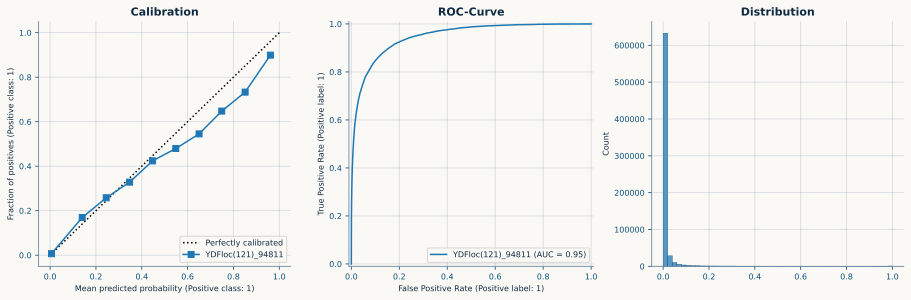

In [39]:
## -- Plot oof distributions --
_, axs = plt.subplots(1, 3, figsize=(12.5, 4))

CalibrationDisplay.from_predictions(y, oof_preds, n_bins=10, name=n, ax=axs[0])
axs[0].set_title(f"Calibration")

RocCurveDisplay.from_predictions(y, oof_preds, name=n, ax=axs[1])
axs[1].set_title(f"ROC-Curve")

sns.histplot(oof_preds, ax=axs[2], bins=50)
axs[2].set_title(f"Distribution")

plt.tight_layout(pad=0.2)
plt.show()

In [40]:
# Check final evaluation metrics computed strictly on the validation set
print(model.validation_evaluation())

# Evaluate the model
evaluation = model.evaluate(pd.concat([X_val, y_val], axis=1))
evaluation

accuracy: 0.986242
confusion matrix:
    label (row) \ prediction (col)
    +--------+--------+--------+
    |        |      0 |      1 |
    +--------+--------+--------+
    |      0 | 137320 |    334 |
    +--------+--------+--------+
    |      1 |   1592 |    746 |
    +--------+--------+--------+
loss: 0.0947403



Label \ Pred,0,1
0,137320,334
1,1592,746


In [41]:
# -- YDF Analysis Report --

analysis = model.analyze(
    pd.concat([X_val, y_val], axis=1),
    sampling = 0.2, # d=1.0
    # num_bins = 100, # d=50
    # permutation_variable_importance_rounds = 2, # d=1
)

analysis # Use ACCURACY & AUC_1_VS_OTHERS